# Initialization, Gradient Flow, and Deep Network Trainability

## Learning Objectives

A neural network may be expressive enough to represent a function and still be
difficult to train.

As networks become deeper, the backward pass has to propagate gradients through
many layers.

This raises several questions:

- how do gradients move through a deep network?
- why can they become extremely small or extremely large?
- how does parameter initialization affect activations and gradients?
- why do activation functions matter for gradient flow?
- what problem do Xavier and He initialization solve?

In this notebook we will deliberately build poorly initialized deep networks,
inspect their activations and gradients layer by layer, and then improve them.

The goal is not to memorize initialization formulas.

The goal is to understand **why those formulas exist**.

The central distinction for this notebook is:

```text
expressivity
→ can the network represent the function?

trainability
→ can optimization actually find useful parameters?
```

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1


## A Deeper Network

In the previous notebook we used only one hidden layer.

Now we will build a deeper network:

```text
input
↓
Linear
↓
ReLU
↓
Linear
↓
ReLU
↓
Linear
↓
ReLU
↓
Linear
↓
output
```

A deeper network repeatedly transforms its internal representation.

During the forward pass:

```text
activations move forward
```

During the backward pass:

```text
gradients move backward
```

The deeper the network becomes, the more transformations both signals must pass
through.

In [2]:
# A batch of 1,000 examples with 32 input features
batch_size = 1000
input_size = 32
hidden_size = 64

x = torch.randn(batch_size, input_size)

print("Input shape:", x.shape)
print("Input mean:", x.mean().item())
print("Input std:", x.std().item())

Input shape: torch.Size([1000, 32])
Input mean: 0.0027107344940304756
Input std: 1.0042102336883545


In [3]:
model = nn.Sequential(
    nn.Linear(32, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 1)
)

print(model)

Sequential(
  (0): Linear(in_features=32, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): ReLU()
  (6): Linear(in_features=64, out_features=64, bias=True)
  (7): ReLU()
  (8): Linear(in_features=64, out_features=1, bias=True)
)


In [4]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Total parameters:", total_params)

Total parameters: 14657


## Why Activation Scale Matters

Suppose the activations become progressively smaller:

```text
1.0
→ 0.3
→ 0.08
→ 0.01
→ 0.001
```

Then deeper layers may receive almost no meaningful signal.

Alternatively, suppose they grow:

```text
1.0
→ 3
→ 15
→ 100
→ 10,000
```

Then the network may become numerically unstable.

Ideally, initialization should keep activation scales reasonably controlled as
signals travel through the network.

We can diagnose this by measuring simple statistics such as:

```text
mean
standard deviation
```

at each layer.

In [5]:
activations = x

print(
    f"{'Input':20s} "
    f"mean={activations.mean().item(): .4f} "
    f"std={activations.std().item(): .4f}"
)

for i, layer in enumerate(model):
    activations = layer(activations)

    print(
        f"Layer {i:2d} "
        f"{layer.__class__.__name__:12s} "
        f"shape={tuple(activations.shape)} "
        f"mean={activations.mean().item(): .4f} "
        f"std={activations.std().item(): .4f}"
    )

Input                mean= 0.0027 std= 1.0042
Layer  0 Linear       shape=(1000, 64) mean=-0.0160 std= 0.5909
Layer  1 ReLU         shape=(1000, 64) mean= 0.2271 std= 0.3389
Layer  2 Linear       shape=(1000, 64) mean= 0.0106 std= 0.2483
Layer  3 ReLU         shape=(1000, 64) mean= 0.1040 std= 0.1468
Layer  4 Linear       shape=(1000, 64) mean= 0.0016 std= 0.1275
Layer  5 ReLU         shape=(1000, 64) mean= 0.0517 std= 0.0744
Layer  6 Linear       shape=(1000, 64) mean=-0.0123 std= 0.0885
Layer  7 ReLU         shape=(1000, 64) mean= 0.0303 std= 0.0494
Layer  8 Linear       shape=(1000, 1) mean= 0.0591 std= 0.0106


## Activation Statistics — Interpretation

The input was approximately standardized:

```text
mean ≈ 0
std  ≈ 1
```

As the signal moved through the network, its standard deviation generally
decreased:

```text
Input       std ≈ 1.004
Linear 1    std ≈ 0.591
ReLU 1      std ≈ 0.339

Linear 2    std ≈ 0.248
ReLU 2      std ≈ 0.147

Linear 3    std ≈ 0.128
ReLU 3      std ≈ 0.074

Linear 4    std ≈ 0.089
ReLU 4      std ≈ 0.049

Output      std ≈ 0.011
```

Two effects are visible.

### Linear layers change signal scale

Each linear layer computes:

$$
z = xW^T + b
$$

The scale of the resulting activations depends strongly on the scale of the
incoming values and the initialized weights.

### ReLU changes the activation distribution

ReLU computes:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

Negative values are replaced with zero.

That changes both the mean and the variance of the distribution.

For example, after the first linear layer:

```text
mean ≈ -0.016
std  ≈ 0.591
```

and after ReLU:

```text
mean ≈ 0.227
std  ≈ 0.339
```

The mean becomes positive because negative activations are clipped to zero.

### Why this matters

By the final layer, the output standard deviation is only approximately:

```text
0.011
```

compared with approximately:

```text
1.004
```

at the input.

This does not by itself prove that the network cannot train.

However, it shows why initialization matters:

> Each layer transforms not only the information in the signal, but also its
> numerical scale.

In sufficiently deep networks, repeatedly shrinking or expanding signals can
make optimization difficult.

Next we will deliberately initialize the weights to extremely small values and
observe a much more severe version of this effect.

## Experiment: Deliberately Tiny Initialization

PyTorch initialized the previous network using sensible defaults.

To understand why initialization matters, we will override those parameters and
make every linear weight extremely small.

Suppose a layer repeatedly multiplies its input by very small weights.

Conceptually:

```text
signal
× small weights
↓
smaller signal
× small weights
↓
even smaller signal
× small weights
↓
almost zero
```

With enough layers, useful variation can disappear.

We will initialize every linear weight from a normal distribution with:

```text
standard deviation = 0.01
```

and set the biases to zero.

Then we will inspect the activation statistics again.

In [6]:
torch.manual_seed(42)

tiny_model = nn.Sequential(
    nn.Linear(32, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 1)
)

# Deliberately bad initialization
with torch.no_grad():
    for layer in tiny_model:
        if isinstance(layer, nn.Linear):
            layer.weight.normal_(mean=0.0, std=0.01)
            layer.bias.zero_()

In [7]:
activations = x

print(
    f"{'Input':20s} "
    f"mean={activations.mean().item(): .8f} "
    f"std={activations.std().item(): .8f}"
)

for i, layer in enumerate(tiny_model):
    activations = layer(activations)

    print(
        f"Layer {i:2d} "
        f"{layer.__class__.__name__:12s} "
        f"shape={tuple(activations.shape)} "
        f"mean={activations.mean().item(): .8f} "
        f"std={activations.std().item(): .8f}"
    )

Input                mean= 0.00271073 std= 1.00421023
Layer  0 Linear       shape=(1000, 64) mean=-0.00027898 std= 0.05754245
Layer  1 ReLU         shape=(1000, 64) mean= 0.02263815 std= 0.03363543
Layer  2 Linear       shape=(1000, 64) mean=-0.00001036 std= 0.00319425
Layer  3 ReLU         shape=(1000, 64) mean= 0.00125376 std= 0.00187942
Layer  4 Linear       shape=(1000, 64) mean=-0.00002356 std= 0.00018982
Layer  5 ReLU         shape=(1000, 64) mean= 0.00006283 std= 0.00010434
Layer  6 Linear       shape=(1000, 64) mean= 0.00000027 std= 0.00000935
Layer  7 ReLU         shape=(1000, 64) mean= 0.00000377 std= 0.00000568
Layer  8 Linear       shape=(1000, 1) mean= 0.00000051 std= 0.00000028


## Tiny Initialization — Interpretation

With weights initialized from:

```text
Normal(mean=0, std=0.01)
```

the forward signal collapsed rapidly through the network.

The activation standard deviation changed approximately as:

```text
Input       1.004
Linear 1    0.0575
ReLU 1      0.0336

Linear 2    0.00319
ReLU 2      0.00188

Linear 3    0.000190
ReLU 3      0.000104

Linear 4    0.00000935
ReLU 4      0.00000568

Output      0.00000028
```

Each layer multiplied its input by very small weights.

Because this happened repeatedly, the signal scale shrank by orders of magnitude.

Conceptually:

```text
meaningful input variation
↓
small weights
↓
smaller activations
↓
small weights again
↓
even smaller activations
↓
...
↓
almost no variation remains
```

By the final layer, many different inputs produce nearly the same output.

This is a forward-pass manifestation of poor initialization.

The next question is even more important:

> What happens to the gradients during backpropagation?

In [8]:
# Synthetic regression target
target = torch.randn(batch_size, 1)

# Forward pass
prediction = tiny_model(x)

loss = ((prediction - target) ** 2).mean()

print("Loss:", loss.item())

# Backward pass
tiny_model.zero_grad()
loss.backward()

Loss: 1.0088934898376465


In [9]:
print(
    f"{'Layer':20s} "
    f"{'weight grad mean':>18s} "
    f"{'weight grad std':>18s} "
    f"{'weight grad max':>18s}"
)

for i, layer in enumerate(tiny_model):
    if isinstance(layer, nn.Linear):
        grad = layer.weight.grad

        print(
            f"Linear layer {i:<7d} "
            f"{grad.abs().mean().item():18.10f} "
            f"{grad.std().item():18.10f} "
            f"{grad.abs().max().item():18.10f}"
        )

Layer                  weight grad mean    weight grad std    weight grad max
Linear layer 0             0.0000000612       0.0000000787       0.0000003296
Linear layer 2             0.0000000419       0.0000000583       0.0000003875
Linear layer 4             0.0000000365       0.0000000603       0.0000004090
Linear layer 6             0.0000000337       0.0000000730       0.0000011636
Linear layer 8             0.0000003615       0.0000003954       0.0000016384


## Tiny Initialization — Gradient Flow

With tiny weights, the forward activations collapsed toward zero.

The backward pass shows a related problem.

Mean absolute weight gradients were approximately:

```text
Layer 0  → 6.12e-8
Layer 2  → 4.19e-8
Layer 4  → 3.65e-8
Layer 6  → 3.37e-8
Layer 8  → 3.62e-7
```

The gradients in the early layers are extremely small.

This means those parameters would update only very slowly.

### Why?

Backpropagation repeatedly applies the chain rule.

For a simplified deep network:

```text
x
→ layer 1
→ layer 2
→ layer 3
→ loss
```

the gradient for an early parameter contains a product of derivatives from all
later operations.

Conceptually:

```text
early-layer gradient
=
later gradient
× derivative
× weight
× derivative
× weight
× ...
```

If many of those multiplicative terms are small, their product becomes very
small.

This is the core mechanism behind **vanishing gradients**.

The important idea is:

> Vanishing gradients are not caused by one small number. They emerge from
> repeatedly multiplying small factors through depth.

## Experiment: Deliberately Large Initialization

Tiny weights caused signals and gradients to shrink toward zero.

Now we will test the opposite failure mode.

If every layer uses weights that are too large, then repeated multiplication can cause
activations to grow rapidly through depth.

Conceptually:

```text
signal
× large weights
↓
larger signal
× large weights
↓
much larger signal
× large weights
↓
possibly unstable values
```

The same issue can affect backpropagation.

Because gradients are also propagated through repeated multiplication, large
factors can cause gradient magnitudes to grow dramatically.

This is the basic mechanism behind **exploding activations** and
**exploding gradients**.

We will initialize every linear weight from:

```text
Normal(mean=0, std=1.0)
```

which is intentionally much larger than a sensible initialization for these
layer sizes.

In [10]:
torch.manual_seed(42)

large_model = nn.Sequential(
    nn.Linear(32, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 1)
)

with torch.no_grad():
    for layer in large_model:
        if isinstance(layer, nn.Linear):
            layer.weight.normal_(mean=0.0, std=1.0)
            layer.bias.zero_()

In [11]:
activations = x

print(
    f"{'Input':20s} "
    f"mean={activations.mean().item(): .6f} "
    f"std={activations.std().item(): .6f}"
)

for i, layer in enumerate(large_model):
    activations = layer(activations)

    print(
        f"Layer {i:2d} "
        f"{layer.__class__.__name__:12s} "
        f"shape={tuple(activations.shape)} "
        f"mean={activations.mean().item(): .6f} "
        f"std={activations.std().item(): .6f}"
    )

Input                mean= 0.002711 std= 1.004210
Layer  0 Linear       shape=(1000, 64) mean=-0.027898 std= 5.754245
Layer  1 ReLU         shape=(1000, 64) mean= 2.263815 std= 3.363543
Layer  2 Linear       shape=(1000, 64) mean=-0.103582 std= 31.942480
Layer  3 ReLU         shape=(1000, 64) mean= 12.537594 std= 18.794182
Layer  4 Linear       shape=(1000, 64) mean=-23.561449 std= 189.824005
Layer  5 ReLU         shape=(1000, 64) mean= 62.832367 std= 104.343430
Layer  6 Linear       shape=(1000, 64) mean= 26.653410 std= 934.765015
Layer  7 ReLU         shape=(1000, 64) mean= 376.537506 std= 567.764343
Layer  8 Linear       shape=(1000, 1) mean= 5058.308594 std= 2786.624023


In [12]:
prediction = large_model(x)

loss = ((prediction - target) ** 2).mean()

print("Loss:", loss.item())

large_model.zero_grad()
loss.backward()

print(
    f"{'Layer':20s} "
    f"{'weight grad mean':>18s} "
    f"{'weight grad std':>18s} "
    f"{'weight grad max':>18s}"
)

for i, layer in enumerate(large_model):
    if isinstance(layer, nn.Linear):
        grad = layer.weight.grad

        print(
            f"Linear layer {i:<7d} "
            f"{grad.abs().mean().item():18.6f} "
            f"{grad.std().item():18.6f} "
            f"{grad.abs().max().item():18.6f}"
        )

Loss: 33344548.0
Layer                  weight grad mean    weight grad std    weight grad max
Linear layer 0             80740.468750      108395.968750      516280.406250
Linear layer 2            190100.093750      262654.593750     1503612.750000
Linear layer 4            226650.250000      425091.625000     3730300.000000
Linear layer 6            313598.500000      704008.750000    10359666.000000
Linear layer 8           4076958.750000     4404898.000000    18176802.000000


## Large Initialization — Interpretation

With weights initialized from:

```text
Normal(mean=0, std=1.0)
```

the network became numerically unstable.

The loss increased to approximately:

```text
33,344,548
```

and the gradient magnitudes became extremely large.

Mean absolute weight gradients were approximately:

```text
Layer 0  → 8.07e4
Layer 2  → 1.90e5
Layer 4  → 2.27e5
Layer 6  → 3.14e5
Layer 8  → 4.08e6
```

The largest individual gradient reached approximately:

```text
1.82e7
```

This is the opposite failure mode from tiny initialization.

With very small weights:

```text
activations shrink
gradients shrink
```

With very large weights:

```text
activations grow
gradients grow
```

The underlying mechanism is again repeated multiplication through depth.

During the forward pass:

```text
activation
× weight
× weight
× weight
...
```

can cause signal magnitudes to grow rapidly.

During the backward pass, the chain rule creates another product of derivatives
and weights.

If many of those factors are large, gradients can grow rapidly as well.

This is the basic mechanism behind **exploding gradients**.

### The initialization problem

A useful initialization should avoid both extremes:

```text
too small
→ vanishing activations and gradients

too large
→ exploding activations and gradients
```

The goal is to preserve a reasonable signal scale as information moves forward
and gradients move backward through the network.

## Why Weight Scale Should Depend on Fan-In

Consider one neuron:

$$
z = \sum_{i=1}^{n} w_i x_i
$$

where:

```text
n
=
number of input features feeding into the neuron
```

This quantity is often called:

```text
fan-in
```

For example:

```text
Linear(32, 64)
→ fan-in = 32

Linear(64, 64)
→ fan-in = 64
```

Suppose the inputs and weights are approximately independent and centered around
zero.

Then the variance of the sum grows roughly like:

$$
\operatorname{Var}(z)
\approx
n
\operatorname{Var}(w)
\operatorname{Var}(x)
$$

This gives an important intuition.

If we choose the same weight variance regardless of layer width:

```text
larger fan-in
→ more terms are added together
→ activation variance tends to grow
```

To keep the output variance from changing too much, we want roughly:

$$
n\operatorname{Var}(w) \approx 1
$$

which suggests:

$$
\operatorname{Var}(w) \approx \frac{1}{n}
$$

and therefore:

$$
\operatorname{Std}(w) \approx \frac{1}{\sqrt{n}}
$$

So a sensible initialization scale should depend on the layer's fan-in.

This is the basic idea behind modern initialization schemes.

In [13]:
import math

for fan_in in [32, 64]:
    scale = 1 / math.sqrt(fan_in)

    print(
        f"fan_in={fan_in:2d} "
        f"→ 1/sqrt(fan_in)={scale:.4f}"
    )

fan_in=32 → 1/sqrt(fan_in)=0.1768
fan_in=64 → 1/sqrt(fan_in)=0.1250


## ReLU Changes the Variance

If a layer were purely linear, a weight scale near:

$$
\frac{1}{\sqrt{\text{fan-in}}}
$$

would be a natural starting point for preserving variance.

But our network uses ReLU.

ReLU removes all negative activations:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

For a roughly symmetric distribution, many activations become zero.

So some signal variance is lost after each ReLU.

To compensate, ReLU networks commonly use a somewhat larger initialization:

$$
\operatorname{Var}(w)
\approx
\frac{2}{\text{fan-in}}
$$

or equivalently:

$$
\operatorname{Std}(w)
\approx
\sqrt{\frac{2}{\text{fan-in}}}
$$

This is commonly called **He initialization** or **Kaiming initialization**.

The goal is not to make activations large.

The goal is to keep their scale reasonably stable as they pass through repeated:

```text
Linear
→ ReLU
```

blocks.

In [15]:
for fan_in in [32, 64]:
    he_std = math.sqrt(2 / fan_in)

    print(
        f"fan_in={fan_in:2d} "
        f"→ He std={he_std:.4f}"
    )

fan_in=32 → He std=0.2500
fan_in=64 → He std=0.1768


## Experiment: He Initialization for ReLU Networks

We will now initialize the same architecture using He initialization.

Instead of manually choosing a fixed standard deviation, PyTorch computes the
appropriate scale from each layer's fan-in.

We will use:

```python
nn.init.kaiming_normal_
```

with:

```text
nonlinearity="relu"
```

Then we will inspect the activation statistics using exactly the same diagnostic
as before.

In [16]:
torch.manual_seed(42)

he_model = nn.Sequential(
    nn.Linear(32, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 64),
    nn.ReLU(),

    nn.Linear(64, 1)
)

with torch.no_grad():
    for layer in he_model:
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(
                layer.weight,
                mode="fan_in",
                nonlinearity="relu"
            )
            layer.bias.zero_()

In [18]:
activations = x

print(
    f"{'Input':20s} "
    f"mean={activations.mean().item(): .6f} "
    f"std={activations.std().item(): .6f}"
)

for i, layer in enumerate(he_model):
    activations = layer(activations)

    print(
        f"Layer {i:2d} "
        f"{layer.__class__.__name__:12s} "
        f"shape={tuple(activations.shape)} "
        f"mean={activations.mean().item(): .6f} "
        f"std={activations.std().item(): .6f}"
    )

Input                mean= 0.002711 std= 1.004210
Layer  0 Linear       shape=(1000, 64) mean=-0.006974 std= 1.438561
Layer  1 ReLU         shape=(1000, 64) mean= 0.565954 std= 0.840886
Layer  2 Linear       shape=(1000, 64) mean=-0.004578 std= 1.411671
Layer  3 ReLU         shape=(1000, 64) mean= 0.554089 std= 0.830593
Layer  4 Linear       shape=(1000, 64) mean=-0.184074 std= 1.483000
Layer  5 ReLU         shape=(1000, 64) mean= 0.490878 std= 0.815183
Layer  6 Linear       shape=(1000, 64) mean= 0.036810 std= 1.290974
Layer  7 ReLU         shape=(1000, 64) mean= 0.520024 std= 0.784121
Layer  8 Linear       shape=(1000, 1) mean= 1.234939 std= 0.680328


In [19]:
prediction = he_model(x)

loss = ((prediction - target) ** 2).mean()

print("Loss:", loss.item())

he_model.zero_grad()
loss.backward()

print(
    f"{'Layer':20s} "
    f"{'weight grad mean':>18s} "
    f"{'weight grad std':>18s} "
    f"{'weight grad max':>18s}"
)

for i, layer in enumerate(he_model):
    if isinstance(layer, nn.Linear):
        grad = layer.weight.grad

        print(
            f"Linear layer {i:<7d} "
            f"{grad.abs().mean().item():18.6f} "
            f"{grad.std().item():18.6f} "
            f"{grad.abs().max().item():18.6f}"
        )

Loss: 3.131948947906494
Layer                  weight grad mean    weight grad std    weight grad max
Linear layer 0                 0.020826           0.027895           0.142896
Linear layer 2                 0.066727           0.092698           0.510325
Linear layer 4                 0.079532           0.148996           1.285746
Linear layer 6                 0.109637           0.245951           3.653672
Linear layer 8                 1.423917           1.534328           6.354972


## He Initialization — Gradient Interpretation

He initialization produced much healthier gradient magnitudes.

Mean absolute gradients were approximately:

```text
Layer 0  → 0.0208
Layer 2  → 0.0667
Layer 4  → 0.0795
Layer 6  → 0.1096
Layer 8  → 1.4239
```

This is very different from the two deliberately bad initializations.

With tiny weights, early gradients were around:

```text
1e-8
```

With very large weights, gradients reached roughly:

```text
1e5 to 1e6
```

With He initialization, gradients remain in a much more practical numerical
range.

The gradients are not identical across layers, nor should we expect them to be.

Different layers:

- receive different activation distributions,
- interact with different ReLU masks,
- have different dimensions,
- and contribute differently to the final loss.

The goal of initialization is not:

```text
make every layer's gradient exactly equal
```

The goal is:

```text
avoid catastrophic shrinking
and
avoid catastrophic growth
```

so useful learning signals can propagate through the network.

In [20]:
activations = x

print(
    f"{'Input':20s} "
    f"mean={activations.mean().item(): .6f} "
    f"std={activations.std().item(): .6f}"
)

for i, layer in enumerate(he_model):
    activations = layer(activations)

    print(
        f"Layer {i:2d} "
        f"{layer.__class__.__name__:12s} "
        f"shape={tuple(activations.shape)} "
        f"mean={activations.mean().item(): .6f} "
        f"std={activations.std().item(): .6f}"
    )

Input                mean= 0.002711 std= 1.004210
Layer  0 Linear       shape=(1000, 64) mean=-0.006974 std= 1.438561
Layer  1 ReLU         shape=(1000, 64) mean= 0.565954 std= 0.840886
Layer  2 Linear       shape=(1000, 64) mean=-0.004578 std= 1.411671
Layer  3 ReLU         shape=(1000, 64) mean= 0.554089 std= 0.830593
Layer  4 Linear       shape=(1000, 64) mean=-0.184074 std= 1.483000
Layer  5 ReLU         shape=(1000, 64) mean= 0.490878 std= 0.815183
Layer  6 Linear       shape=(1000, 64) mean= 0.036810 std= 1.290974
Layer  7 ReLU         shape=(1000, 64) mean= 0.520024 std= 0.784121
Layer  8 Linear       shape=(1000, 1) mean= 1.234939 std= 0.680328


## He Initialization — Activation Interpretation

He initialization kept the activation scale much more stable across depth.

The standard deviations were approximately:

```text
Input       1.004

Linear 1    1.439
ReLU 1      0.841

Linear 2    1.412
ReLU 2      0.831

Linear 3    1.483
ReLU 3      0.815

Linear 4    1.291
ReLU 4      0.784

Output      0.680
```

Unlike the tiny initialization experiment, the signal does not progressively
collapse toward zero.

The linear layers temporarily increase the variance, while ReLU reduces it by
zeroing negative activations.

Together, the `Linear → ReLU` blocks maintain a relatively stable signal scale.

This is the behavior He initialization is designed to encourage.

### Important nuance

The goal is not:

```text
std = exactly 1.0 at every layer
```

Real neural networks contain:

- finite-width layers,
- random samples,
- nonlinear activations,
- learned biases,
- correlations between activations,
- and different output dimensions.

So exact variance preservation is not expected.

The practical goal is much broader:

> Keep the signal in a numerically useful range instead of allowing it to
> systematically vanish or explode with depth.

## Initialization Should Match the Activation

He initialization is particularly well suited to ReLU-like activations.

But different activation functions transform signal distributions differently.

One important historical example is:

$$
\tanh(z)
$$

whose output lies between:

$$
-1 \leq \tanh(z) \leq 1
$$

Unlike ReLU, `tanh`:

- keeps both positive and negative outputs,
- is centered around zero,
- is approximately linear near zero,
- but saturates for large positive or negative inputs.

For networks using activations such as `tanh`, another common initialization is
**Xavier initialization**, also called **Glorot initialization**.

The central goal remains the same:

```text
preserve useful signal scale
through the forward pass
and
through the backward pass
```

but the appropriate variance depends on the network structure and activation.

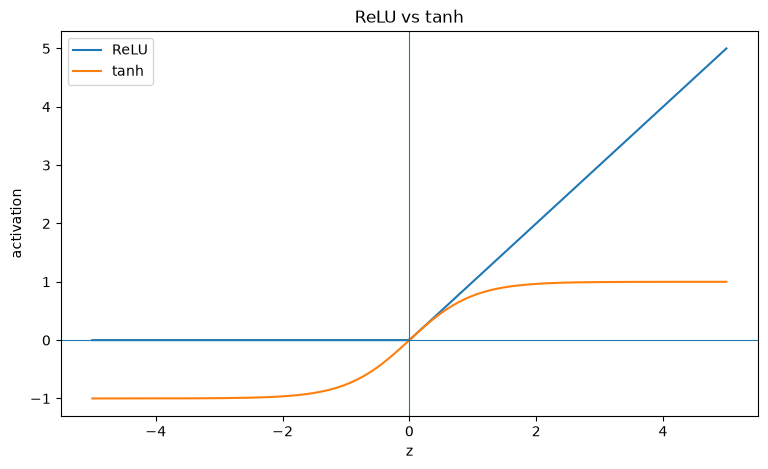

In [21]:
z = torch.linspace(-5, 5, 200)

relu_z = torch.relu(z)
tanh_z = torch.tanh(z)

plt.figure(figsize=(9, 5))

plt.plot(
    z.numpy(),
    relu_z.numpy(),
    label="ReLU"
)

plt.plot(
    z.numpy(),
    tanh_z.numpy(),
    label="tanh"
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("z")
plt.ylabel("activation")
plt.title("ReLU vs tanh")
plt.legend()
plt.show()

## Why Saturation Matters

For `tanh`, the derivative is:

$$
\frac{d}{dz}\tanh(z)
=
1-\tanh^2(z)
$$

Near:

$$
z=0
$$

we have:

$$
\tanh(z)\approx 0
$$

so:

$$
\frac{d}{dz}\tanh(z)\approx 1
$$

This means gradients can pass through relatively well.

But when $|z|$ becomes large:

$$
\tanh(z)\approx \pm 1
$$

so:

$$
1-\tanh^2(z)\approx 0
$$

and therefore:

```text
gradient passed backward
→ very small
```

This is called **saturation**.

A saturated activation is not necessarily numerically large.

In fact, `tanh` outputs remain bounded between `-1` and `1`.

The problem is that the function becomes nearly flat, so its derivative becomes
very small.

This creates another route to vanishing gradients:

```text
large pre-activation
↓
tanh saturates
↓
derivative ≈ 0
↓
gradient shrinks
```

Initialization therefore needs to control not only activation magnitude, but also
where activations lie on the nonlinear function.

## Experiment: Large Weights in a `tanh` Network

We will build the same deep architecture using `tanh` instead of ReLU.

First, we will deliberately initialize the weights too large.

We will then measure:

- activation standard deviation,
- fraction of activations near `-1` or `+1`,
- gradient magnitudes.

For this experiment, we will call a `tanh` activation **saturated** when:

$$
|\tanh(z)| > 0.95
$$

This is not a universal threshold. It is simply a useful diagnostic for showing
how many neurons have entered the nearly-flat regions of the activation.

In [23]:
torch.manual_seed(42)

large_tanh_model = nn.Sequential(
    nn.Linear(32, 64),
    nn.Tanh(),

    nn.Linear(64, 64),
    nn.Tanh(),

    nn.Linear(64, 64),
    nn.Tanh(),

    nn.Linear(64, 64),
    nn.Tanh(),

    nn.Linear(64, 1)
)

with torch.no_grad():
    for layer in large_tanh_model:
        if isinstance(layer, nn.Linear):
            layer.weight.normal_(mean=0.0, std=1.0)
            layer.bias.zero_()

In [24]:
activations = x

print(
    f"{'Layer':20s} "
    f"{'mean':>12s} "
    f"{'std':>12s} "
    f"{'saturated %':>14s}"
)

print(
    f"{'Input':20s} "
    f"{activations.mean().item():12.6f} "
    f"{activations.std().item():12.6f} "
    f"{'-':>14s}"
)

for i, layer in enumerate(large_tanh_model):
    activations = layer(activations)

    if isinstance(layer, nn.Tanh):
        saturated_fraction = (
            activations.abs() > 0.95
        ).float().mean().item() * 100

        saturated_text = f"{saturated_fraction:.2f}%"
    else:
        saturated_text = "-"

    print(
        f"Layer {i:2d} {layer.__class__.__name__:12s} "
        f"{activations.mean().item():12.6f} "
        f"{activations.std().item():12.6f} "
        f"{saturated_text:>14s}"
    )

Layer                        mean          std    saturated %
Input                    0.002711     1.004210              -
Layer  0 Linear          -0.027898     5.754245              -
Layer  1 Tanh            -0.005384     0.927450         74.50%
Layer  2 Linear          -0.034036     7.441083              -
Layer  3 Tanh            -0.006900     0.945924         80.64%
Layer  4 Linear          -0.019602     7.549272              -
Layer  5 Tanh            -0.003899     0.946012         80.76%
Layer  6 Linear           0.010788     7.593340              -
Layer  7 Tanh             0.000873     0.945818         80.79%
Layer  8 Linear          -0.151676     6.843387              -


In [25]:
prediction = large_tanh_model(x)

loss = ((prediction - target) ** 2).mean()

print("Loss:", loss.item())

large_tanh_model.zero_grad()
loss.backward()

print(
    f"{'Layer':20s} "
    f"{'weight grad mean':>18s} "
    f"{'weight grad std':>18s} "
    f"{'weight grad max':>18s}"
)

for i, layer in enumerate(large_tanh_model):
    if isinstance(layer, nn.Linear):
        grad = layer.weight.grad

        print(
            f"Linear layer {i:<7d} "
            f"{grad.abs().mean().item():18.8f} "
            f"{grad.std().item():18.8f} "
            f"{grad.abs().max().item():18.8f}"
        )

Loss: 47.43155288696289
Layer                  weight grad mean    weight grad std    weight grad max
Linear layer 0               1.05613887         1.37251937         7.43860912
Linear layer 2               0.39900136         0.51229745         1.92412853
Linear layer 4               0.20607325         0.27306002         1.46134531
Linear layer 6               0.13599168         0.21380697         1.77800512
Linear layer 8               1.59828568         1.98390293         4.31501341


## Large `tanh` Initialization — Interpretation

Large weights produced very large pre-activations:

```text
Linear 1 std ≈ 5.75
Linear 2 std ≈ 7.44
Linear 3 std ≈ 7.55
Linear 4 std ≈ 7.59
```

However, the `tanh` outputs remained bounded:

```text
Tanh std ≈ 0.93–0.95
```

Looking only at the activation standard deviation might therefore suggest that
the network is numerically well behaved.

The saturation diagnostic reveals the real problem:

```text
Tanh 1 → 74.50% saturated
Tanh 2 → 80.64% saturated
Tanh 3 → 80.76% saturated
Tanh 4 → 80.79% saturated
```

Most hidden activations are close to either `-1` or `+1`.

In these regions:

$$
\frac{d}{dz}\tanh(z)
=
1-\tanh^2(z)
\approx 0
$$

so relatively little gradient can pass through the activation.

### An important distinction

A network can have:

```text
bounded activations
```

without having:

```text
healthy gradient flow
```

`tanh` prevents its output values from exploding numerically, but excessively
large pre-activations push the neurons into saturated regions where their
derivatives are small.

The failure mechanism is therefore different from the large-ReLU experiment:

```text
large weights + ReLU
→ exploding activation magnitudes
→ exploding gradients

large weights + tanh
→ bounded outputs
→ heavy saturation
→ small activation derivatives
```

Initialization must therefore account for the activation function, not merely
keep numerical values finite.

## Xavier Initialization

For activations that are roughly symmetric around zero, such as `tanh`, a common
initialization strategy is **Xavier initialization**, also known as **Glorot
initialization**.

The idea is to choose the weight scale using both:

```text
fan-in
→ number of inputs entering the layer

fan-out
→ number of outputs leaving the layer
```

For Xavier normal initialization:

$$
\operatorname{Var}(W)
=
\frac{2}
{\text{fan-in}+\text{fan-out}}
$$

and therefore:

$$
\operatorname{Std}(W)
=
\sqrt{
\frac{2}
{\text{fan-in}+\text{fan-out}}
}
$$

Using both fan-in and fan-out is a compromise intended to keep signal scales
reasonable in both the forward and backward directions.

For a `64 → 64` layer:

$$
\operatorname{Std}(W)
=
\sqrt{\frac{2}{64+64}}
=
\sqrt{\frac{1}{64}}
=
0.125
$$

Compare this with the deliberately bad initialization:

```text
large tanh experiment → std = 1.0
Xavier for 64 → 64    → std ≈ 0.125
```

Xavier therefore begins with substantially smaller weights, helping keep `tanh`
pre-activations near its responsive, non-saturated region.

In [26]:
torch.manual_seed(42)

xavier_tanh_model = nn.Sequential(
    nn.Linear(32, 64),
    nn.Tanh(),

    nn.Linear(64, 64),
    nn.Tanh(),

    nn.Linear(64, 64),
    nn.Tanh(),

    nn.Linear(64, 64),
    nn.Tanh(),

    nn.Linear(64, 1)
)

with torch.no_grad():
    for layer in xavier_tanh_model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_normal_(layer.weight)
            layer.bias.zero_()

In [27]:
activations = x

print(
    f"{'Layer':20s} "
    f"{'mean':>12s} "
    f"{'std':>12s} "
    f"{'saturated %':>14s}"
)

print(
    f"{'Input':20s} "
    f"{activations.mean().item():12.6f} "
    f"{activations.std().item():12.6f} "
    f"{'-':>14s}"
)

for i, layer in enumerate(xavier_tanh_model):
    activations = layer(activations)

    if isinstance(layer, nn.Tanh):
        saturated_fraction = (
            activations.abs() > 0.95
        ).float().mean().item() * 100

        saturated_text = f"{saturated_fraction:.2f}%"
    else:
        saturated_text = "-"

    print(
        f"Layer {i:2d} {layer.__class__.__name__:12s} "
        f"{activations.mean().item():12.6f} "
        f"{activations.std().item():12.6f} "
        f"{saturated_text:>14s}"
    )

Layer                        mean          std    saturated %
Input                    0.002711     1.004210              -
Layer  0 Linear          -0.004027     0.830554              -
Layer  1 Tanh            -0.002828     0.568674          2.96%
Layer  2 Linear          -0.003646     0.573246              -
Layer  3 Tanh            -0.003198     0.457129          0.17%
Layer  4 Linear          -0.001395     0.451669              -
Layer  5 Tanh            -0.001380     0.385994          0.00%
Layer  6 Linear           0.000754     0.389534              -
Layer  7 Tanh             0.000509     0.343680          0.00%
Layer  8 Linear          -0.017022     0.344236              -


In [28]:
prediction = xavier_tanh_model(x)

loss = ((prediction - target) ** 2).mean()

print("Loss:", loss.item())

xavier_tanh_model.zero_grad()
loss.backward()

print(
    f"{'Layer':20s} "
    f"{'weight grad mean':>18s} "
    f"{'weight grad std':>18s} "
    f"{'weight grad max':>18s}"
)

for i, layer in enumerate(xavier_tanh_model):
    if isinstance(layer, nn.Linear):
        grad = layer.weight.grad

        print(
            f"Linear layer {i:<7d} "
            f"{grad.abs().mean().item():18.8f} "
            f"{grad.std().item():18.8f} "
            f"{grad.abs().max().item():18.8f}"
        )

Loss: 1.1230393648147583
Layer                  weight grad mean    weight grad std    weight grad max
Linear layer 0               0.00466081         0.00724951         0.04621493
Linear layer 2               0.00521752         0.00837766         0.05641929
Linear layer 4               0.00712065         0.01093965         0.08945094
Linear layer 6               0.00892536         0.01359764         0.09697205
Linear layer 8               0.06120089         0.07672631         0.20589852


## Xavier Initialization — Interpretation

Xavier initialization dramatically changed the behavior of the `tanh` network.

With deliberately large weights, saturation was:

```text
Tanh 1 → 74.50%
Tanh 2 → 80.64%
Tanh 3 → 80.76%
Tanh 4 → 80.79%
```

With Xavier initialization:

```text
Tanh 1 → 2.96%
Tanh 2 → 0.17%
Tanh 3 → 0.00%
Tanh 4 → 0.00%
```

The pre-activation standard deviations were also much smaller:

```text
Large initialization:
≈ 5.75 to 7.59

Xavier initialization:
≈ 0.39 to 0.83
```

This keeps most `tanh` units away from the saturated regions near `-1` and `+1`.

The loss also dropped substantially:

```text
Large initialization → loss ≈ 47.43
Xavier initialization → loss ≈ 1.12
```

Gradient magnitudes remained in a much more controlled range:

```text
Layer 0 → 0.00466
Layer 2 → 0.00522
Layer 4 → 0.00712
Layer 6 → 0.00893
Layer 8 → 0.06120
```

The key idea is:

> Xavier initialization does not make every activation or gradient identical.
> It places the network in a numerically useful regime where signals and
> gradients can propagate without immediately collapsing, exploding, or
> saturating.

## He vs Xavier — The Mental Model

Both initialization methods try to preserve useful signal scale through depth.

They differ because activation functions transform distributions differently.

### He / Kaiming initialization

For ReLU-like activations:

$$
\operatorname{Var}(W)
\approx
\frac{2}{\text{fan-in}}
$$

The factor of `2` compensates for the fact that ReLU removes negative activations.

Typical pairing:

```text
Linear
→ ReLU / LeakyReLU
→ He initialization
```

### Xavier / Glorot initialization

For roughly symmetric activations such as `tanh`:

$$
\operatorname{Var}(W)
=
\frac{2}
{\text{fan-in}+\text{fan-out}}
$$

Typical pairing:

```text
Linear
→ tanh
→ Xavier initialization
```

The important principle is not to memorize:

```text
ReLU = He
tanh = Xavier
```

as an isolated rule.

Instead remember:

> Initialization should be chosen so that the activation distribution and
> gradient distribution remain useful as signals propagate through depth.

# What We Learned

A deep network may be expressive enough to represent a solution and still be
difficult to optimize.

We observed several failure modes directly.

## 1. Tiny weights can collapse the forward signal

With:

```text
weight std = 0.01
```

the activation standard deviation fell from approximately:

```text
1.0
```

to:

```text
2.8e-7
```

by the output layer.

Early-layer gradients were around:

```text
1e-8
```

This demonstrated vanishing signal and gradient behavior.

## 2. Large weights can cause exploding signals and gradients

With ReLU and:

```text
weight std = 1.0
```

the loss grew to approximately:

```text
3.3e7
```

and some gradients reached approximately:

```text
1.8e7
```

## 3. Activation functions create different failure modes

`tanh` prevents its outputs from becoming numerically large because:

$$
-1 \leq \tanh(z) \leq 1
$$

But large pre-activations caused roughly:

```text
75–81%
```

of the hidden units to saturate.

Bounded outputs therefore do not guarantee healthy gradient flow.

## 4. Initialization should depend on layer structure

The number of incoming connections matters.

For a neuron:

$$
z=\sum_i w_ix_i
$$

adding many independent terms changes the variance of the result.

This motivates scaling weights according to quantities such as:

```text
fan-in
fan-out
```

rather than choosing an arbitrary fixed standard deviation.

## 5. He initialization works well with ReLU

He initialization preserved activation scales much more effectively in the
ReLU network.

Instead of collapsing toward zero or exploding, hidden activation standard
deviations remained around:

```text
0.78–0.84
```

in this experiment.

## 6. Xavier initialization reduces `tanh` saturation

With Xavier initialization, `tanh` saturation fell from roughly:

```text
75–81%
```

to:

```text
3% → 0%
```

across depth.

## 7. Gradient flow is a chain-rule phenomenon

Backpropagation repeatedly multiplies local derivatives.

Conceptually:

```text
gradient
× derivative
× weight
× derivative
× weight
× ...
```

Repeated factors smaller than one can produce vanishing gradients.

Repeated large factors can produce exploding gradients.

Good initialization helps keep that chain in a useful numerical regime.

---

The next question is:

> Once initialization gives us a trainable network, how do depth, normalization,
> residual connections, and optimization choices affect training in practice?